In [1]:
import os
os.environ['CUDA_VISIBLE_DEVICES'] = '0'
os.environ['XLA_PYTHON_CLIENT_MEM_FRACTION'] = '0.4'
os.environ['OMP_NUM_THREADS']='1'
os.environ['XLA_FLAGS'] = (
    '--xla_gpu_triton_gemm_any=True '
    '--xla_gpu_enable_latency_hiding_scheduler=true '
)
#os.environ["TF_CUDNN_DETERMINISTIC"] = "1"
#os.environ['XLA_FLAGS']='--xla_gpu_deterministic_reductions --xla_gpu_autotune_level=1'

os.environ.update({
  "NCCL_LL128_BUFFSIZE": "-2",
  "NCCL_LL_BUFFSIZE": "-2",
   "NCCL_PROTO": "SIMPLE,LL,LL128",
 })


from models import scalar, gauge
import pickle
import sys
import time
from typing import Callable, Sequence

import flax
import flax.linen as nn
import jax
import jax.numpy as jnp
import numpy as np
import optax
#import sympy
#import optuna
from util import *
from itertools import product
from functools import partial


import matplotlib
import matplotlib.pyplot as plt
import scipy.special as special

matplotlib.style.use('default') # 'classic'
matplotlib.rcParams['font.family'] = 'STIXGeneral'
# matplotlib.rcParams['axes.prop_cycle'] = plt.cycler(color='krbg')
matplotlib.rcParams['legend.numpoints'] = 1

%load_ext autoreload
%autoreload 2

@jax.jit
def arcsinh(x: any) -> any:
    return jnp.arcsinh(x)


@jax.jit
def sinh(x: any) -> any:
    return jnp.sinh(x)

jax.config.update("jax_default_matmul_precision", "highest")
# jax.config.update("jax_enable_x64", True)

# jax.config.update("jax_platform_name","cpu")
num_devices = jax.local_device_count()
jax.devices()

# jax.config.values

[CpuDevice(id=0)]

In [2]:
class MLP(nn.Module):
    volume: int
    features: Sequence[int]
    kernel_init: Callable = nn.initializers.variance_scaling(
        2, "fan_in", "truncated_normal")  # for ReLU / CELU
    bias_init: Callable = nn.initializers.zeros

    @nn.compact
    def __call__(self, x):
        for feat in self.features:
            x = nn.Dense(feat, use_bias=False,
                         kernel_init=self.kernel_init,
                         bias_init=self.bias_init)(x)
            x = arcsinh(x)
        x = nn.Dense(1, use_bias=False,
                     kernel_init=self.bias_init)(x)
        return x


class CV_MLP(nn.Module):
    volume: int
    features: Sequence[int]

    @nn.compact
    def __call__(self, x):
        x = MLP(self.volume, self.features)(x)
        y = self.param('bias', nn.initializers.zeros, (1,))
        return x, y


jack bin size 1: (np.float32(0.0035599817), np.complex128(0.00011990010885560842+0j))
bin size 1: (np.float32(0.0035599817), np.complex128(0.00011990134551381811+0j))
jack bin size 2: (np.float32(0.0035599817), np.complex128(0.00016616923800916614+0j))
bin size 2: (np.float32(0.0035599817), np.complex128(0.00016616854843756865+0j))
jack bin size 4: (np.float32(0.0035599817), np.complex128(0.00022852820528731658+0j))
bin size 4: (np.float32(0.0035599817), np.complex128(0.0002285271755981584+0j))
jack bin size 5: (np.float32(0.0035599817), np.complex128(0.000252333894924349+0j))
bin size 5: (np.float32(0.0035599817), np.complex128(0.0002523335635520957+0j))
jack bin size 10: (np.float32(0.0035599817), np.complex128(0.0003383680647163182+0j))
bin size 10: (np.float32(0.0035599817), np.complex128(0.0003383683100943418+0j))
jack bin size 20: (np.float32(0.0035599817), np.complex128(0.0004391619184387924+0j))
bin size 20: (np.float32(0.0035599817), np.complex128(0.00043916189680241264+0j))
j

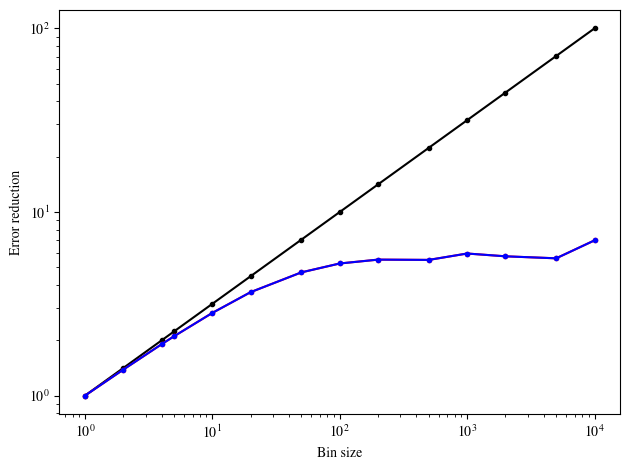

In [3]:
with open("1+1scalar/config/c_16x16_0.1_0.5_sweep1.pkl", "rb") as aa:
    conf = pickle.load(aa)

model =  eval("scalar.Model(geom=(16,16), m2=0.1, lamda=0.5)")
V=model.dof

obs = jax.vmap(lambda x: model.observe(x, model.shape[0]//2))(conf)

error_jac, error_bi = [], []

for i in 1, 2, 4, 5, 10, 20, 50, 100,200, 500, 1000, 2000, 5000, 10000:
    jac, bi = jackknife(obs[:100000], Bs=i), bin(obs[:100000], Bs=i)
    print(f"jack bin size {i}: {jac}")
    print(f"bin size {i}: {bi}")
    error_jac.append(jac[1].real)
    error_bi.append(bi[1].real)

x_axis = np.array([1, 2, 4, 5, 10, 20, 50, 100,200, 500, 1000, 2000, 5000, 10000])

plt.plot(x_axis, np.sqrt(x_axis), color='black', marker='.', linestyle='-')
plt.plot(x_axis, np.array(error_jac)/error_jac[0], color='red', marker='.', linestyle='-')
plt.plot(x_axis, np.array(error_bi)/error_bi[0], color='blue', marker='.', linestyle='-')
plt.xscale('log')
plt.yscale('log')

plt.xlabel('Bin size')
plt.ylabel('Error reduction')
plt.tight_layout()
#plt.legend()
plt.show()

In [4]:
with open("correlated/scalar2d/cv_16x16_0.1_0.5_l2_w32_lr1e-4_nt32_ridge0_test1e3_train1e4_sweep1_bs1_10min.pkl", "rb") as aa:
    g1, g_params, opt_state, track_red_temp, track_ltest_temp = pickle.load(aa)

In [5]:
index = jnp.array([
    tuple(-x for x in coords)
    for coords in product(*(range(dim) for dim in model.shape))
])


def g(x, p):
    def g_(x, p, ind):
        rolled_x = jnp.roll(x.reshape(model.shape), shift=ind, axis=tuple(
            range(len(model.shape)))).reshape(-1)

        return g1.apply(p, rolled_x)[0]
    return jnp.ravel(jax.vmap(lambda ind: g_(x, p, ind))(index).T)


dS = jax.grad(lambda y: model.action(y).real)


@jax.jit
def f(x, p):
    # diagonal sum (Stein's identity)
    def diag_(ind):
        rolled_x = jnp.roll(x.reshape(model.shape), shift=ind, axis=tuple(
            range(len(model.shape)))).reshape(-1)

        ei = jnp.zeros_like(x).at[0].set(1.0)
        _, jvp_val = jax.jvp(lambda y: g1.apply(p, y)[0], (rolled_x,), (ei,))

        return jvp_val[0]
    j = jax.vmap(diag_)(index).sum()
    return j - g(x, p)@dS(x)

jack bin size 1: (np.float32(-0.00053369964), np.complex128(0.00011912111890937918+0j))
bin size 1: (np.float32(-0.00053369964), np.complex128(0.00011912119625191053+0j))
jack bin size 2: (np.float32(-0.00053369964), np.complex128(0.00016505994639151334+0j))
bin size 2: (np.float32(-0.00053369964), np.complex128(0.00016505969741707944+0j))
jack bin size 4: (np.float32(-0.00053369964), np.complex128(0.00022697866111543745+0j))
bin size 4: (np.float32(-0.00053369964), np.complex128(0.0002269786814295599+0j))
jack bin size 5: (np.float32(-0.00053369964), np.complex128(0.00025062080560086684+0j))
bin size 5: (np.float32(-0.00053369964), np.complex128(0.0002506206201209313+0j))
jack bin size 10: (np.float32(-0.00053369964), np.complex128(0.00033603364497081445+0j))
bin size 10: (np.float32(-0.00053369964), np.complex128(0.00033603370294263163+0j))
jack bin size 20: (np.float32(-0.00053369964), np.complex128(0.0004360739172178504+0j))
bin size 20: (np.float32(-0.00053369964), np.complex128(0

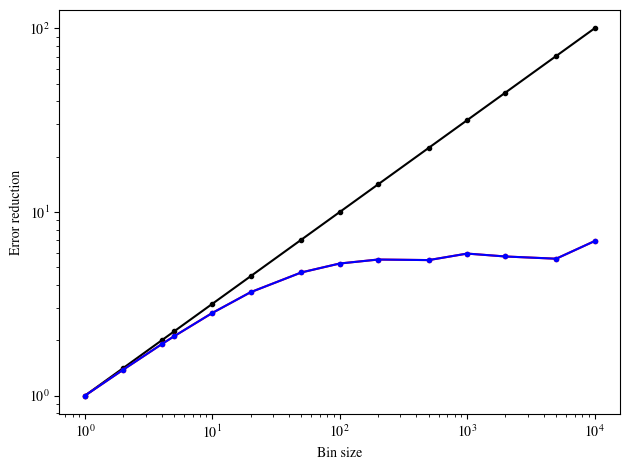

In [6]:

obs = jax.vmap(lambda x: f(x, g_params))(conf)

error_jac, error_bi = [], []

for i in 1, 2, 4, 5, 10, 20, 50, 100,200, 500, 1000, 2000, 5000, 10000:
    jac, bi = jackknife(obs[:100000], Bs=i), bin(obs[:100000], Bs=i)
    print(f"jack bin size {i}: {jac}")
    print(f"bin size {i}: {bi}")
    error_jac.append(jac[1].real)
    error_bi.append(bi[1].real)

x_axis = np.array([1, 2, 4, 5, 10, 20, 50, 100,200, 500, 1000, 2000, 5000, 10000])

plt.plot(x_axis, np.sqrt(x_axis), color='black', marker='.', linestyle='-')
plt.plot(x_axis, np.array(error_jac)/error_jac[0], color='red', marker='.', linestyle='-')
plt.plot(x_axis, np.array(error_bi)/error_bi[0], color='blue', marker='.', linestyle='-')
plt.xscale('log')
plt.yscale('log')

plt.xlabel('Bin size')
plt.ylabel('Error reduction')
plt.tight_layout()
#plt.legend()
plt.show()

jack bin size 1: (np.float32(0.004093672), np.complex128(5.590815373882412e-06+0j))
bin size 1: (np.float32(0.004093672), np.complex128(5.5905765262383755e-06+0j))
jack bin size 2: (np.float32(0.004093672), np.complex128(6.8513269543788364e-06+0j))
bin size 2: (np.float32(0.004093672), np.complex128(6.851066963865548e-06+0j))
jack bin size 4: (np.float32(0.004093672), np.complex128(8.340960084308182e-06+0j))
bin size 4: (np.float32(0.004093672), np.complex128(8.340993514582584e-06+0j))
jack bin size 5: (np.float32(0.004093672), np.complex128(8.8667420884962e-06+0j))
bin size 5: (np.float32(0.004093672), np.complex128(8.866933255574411e-06+0j))
jack bin size 10: (np.float32(0.004093672), np.complex128(1.0558811378283569e-05+0j))
bin size 10: (np.float32(0.004093672), np.complex128(1.055875386386558e-05+0j))
jack bin size 20: (np.float32(0.004093672), np.complex128(1.217142965332826e-05+0j))
bin size 20: (np.float32(0.004093672), np.complex128(1.2171223411484012e-05+0j))
jack bin size 50

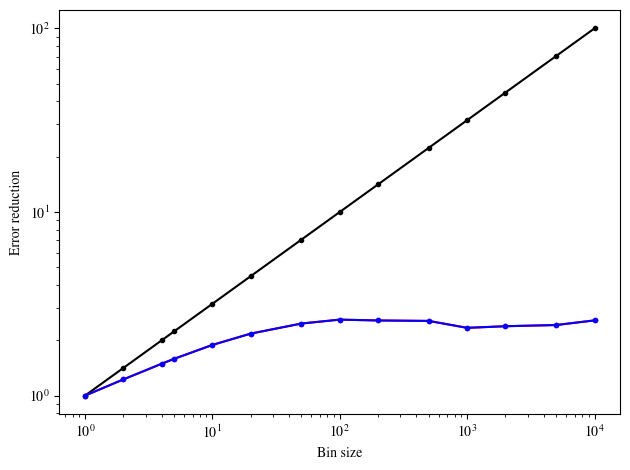

In [7]:

obs = jax.vmap(lambda x: model.observe(x, model.shape[0]//2) -  f(x, g_params))(conf)

error_jac, error_bi = [], []

for i in 1, 2, 4, 5, 10, 20, 50, 100,200, 500, 1000, 2000, 5000, 10000:
    jac, bi = jackknife(obs[:100000], Bs=i), bin(obs[:100000], Bs=i)
    print(f"jack bin size {i}: {jac}")
    print(f"bin size {i}: {bi}")
    error_jac.append(jac[1].real)
    error_bi.append(bi[1].real)

x_axis = np.array([1, 2, 4, 5, 10, 20, 50, 100,200, 500, 1000, 2000, 5000, 10000])

plt.plot(x_axis, np.sqrt(x_axis), color='black', marker='.', linestyle='-')
plt.plot(x_axis, np.array(error_jac)/error_jac[0], color='red', marker='.', linestyle='-')
plt.plot(x_axis, np.array(error_bi)/error_bi[0], color='blue', marker='.', linestyle='-')
plt.xscale('log')
plt.yscale('log')

plt.xlabel('Bin size')
plt.ylabel('Error reduction')
plt.tight_layout()
#plt.legend()
plt.show()

jack bin size 1: (np.complex64(-2.9661838e-05-2.1275944e-06j), np.complex128(6.220078289917983e-06+1.7739685174608938e-06j))
bin size 1: (np.complex64(-2.9661838e-05-2.1275944e-06j), np.complex128(6.220093080431172e-06+1.773973633314314e-06j))
jack bin size 2: (np.complex64(-2.9661838e-05-2.1275944e-06j), np.complex128(8.704278271858911e-06+2.476129080208468e-06j))
bin size 2: (np.complex64(-2.9661838e-05-2.1275944e-06j), np.complex128(8.70426319973095e-06+2.4761275895052843e-06j))
jack bin size 4: (np.complex64(-2.9661838e-05-2.1275944e-06j), np.complex128(1.2122854245043763e-05+3.434080879411266e-06j))
bin size 4: (np.complex64(-2.9661838e-05-2.1275944e-06j), np.complex128(1.21228492363043e-05+3.434084296054211e-06j))
jack bin size 5: (np.complex64(-2.9661838e-05-2.1275944e-06j), np.complex128(1.345323075038619e-05+3.804716967651345e-06j))
bin size 5: (np.complex64(-2.9661838e-05-2.1275944e-06j), np.complex128(1.3453225130972717e-05+3.8047191223870575e-06j))
jack bin size 10: (np.com

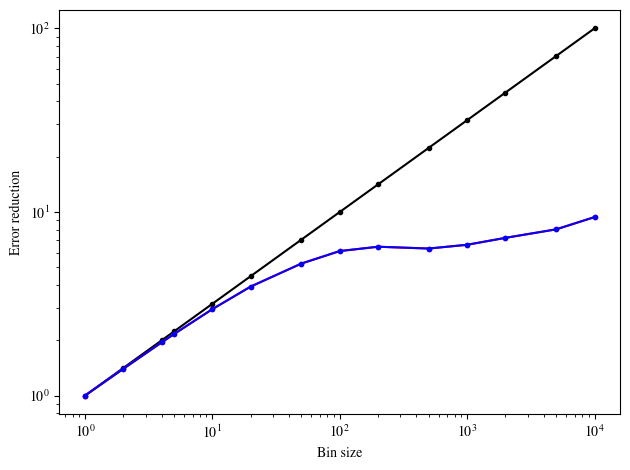

In [2]:
model=eval("gauge.U1_3D_PBC(geom=(4, 4, 8),beta=5.55)")
V= model.dof
 
with open("u1_3d_pbc/config/c_4x4x8_5.55_single_sweep4.pkl", 'rb') as aa:
    conf = jnp.array(pickle.load(aa))

conf = jnp.log(conf).imag.reshape([len(conf), model.dof])

plaq_av_pmap = jax.pmap(jax.vmap(model.plaq_av))

av = jnp.mean(plaq_av_pmap(conf[:200000].reshape(num_devices,200000//num_devices,-1)), axis=(0, 1))

V = model.dof

av = jnp.mean(jax.vmap(model.plaq_av)(conf),axis = 0)

obs = jax.lax.map(lambda x: model.correlation(x, 4, av), conf, batch_size=1000)

error_jac, error_bi = [], []

for i in 1, 2, 4, 5, 10, 20, 50, 100,200, 500, 1000, 2000, 5000, 10000:
    jac, bi = jackknife(obs[:100000], Bs=i), bin(obs[:100000], Bs=i)
    print(f"jack bin size {i}: {jac}")
    print(f"bin size {i}: {bi}")
    error_jac.append(jac[1].real)
    error_bi.append(bi[1].real)

x_axis = np.array([1, 2, 4, 5, 10, 20, 50, 100,200, 500, 1000, 2000, 5000, 10000])

plt.plot(x_axis, np.sqrt(x_axis), color='black', marker='.', linestyle='-')
plt.plot(x_axis, np.array(error_jac)/error_jac[0], color='red', marker='.', linestyle='-')
plt.plot(x_axis, np.array(error_bi)/error_bi[0], color='blue', marker='.', linestyle='-')
plt.xscale('log')
plt.yscale('log')

plt.xlabel('Bin size')
plt.ylabel('Error reduction')
plt.tight_layout()
#plt.legend()
plt.show()

In [2]:
## celu activation

class MLP(nn.Module):
    volume: int
    features: Sequence[int]
    bias: bool
    kernel_init: Callable = nn.initializers.variance_scaling(
        2, "fan_in", "truncated_normal")  # for ReLU / CELU
    bias_init: Callable = nn.initializers.zeros

    @nn.compact
    def __call__(self, x):
        for feat in self.features:
            x = nn.Dense(feat, use_bias=self.bias,
                         kernel_init=self.kernel_init,
                         bias_init=self.bias_init)(x)
            x = nn.celu(x)
            #x = arcsinh(x)
            # x = nn.leaky_relu(x, negative_slope=0.01) #nn.relu jnp.tan nn.tanh #nn.celu
        x = nn.Dense(2, use_bias=self.bias,
                     kernel_init=self.bias_init, bias_init = self.bias_init)(x) ### adfasdfadsf
        return x

class CV_MLP_Periodic(nn.Module):
    volume: int
    features: Sequence[int]
    n: int

    @nn.compact
    def __call__(self, x):
        pl = model.plaquette(x)

        powers = jnp.array([pl**i for i in range(1, self.n+1)])
        sinx = jnp.hstack((powers.imag, powers.real))[0]
        
        g0 = MLP(self.volume, self.features, True)(sinx)
        # g1 = MLP(self.volume, self.features, True)(sinx)

        y = self.param('bias', nn.initializers.zeros, (1,))
        return g0, y

In [4]:
with open("correlated/u1_3d/cv_4x4x8_5.55_dt4_l2_w32_lr1e-4_nt32_ridge0_test1e3_train1e4_sweep4_bs1_2h.pkl", "rb") as aa:
    g1, g_params, opt_state, track_red_temp, track_ltest_temp = pickle.load(aa)
        

In [5]:
index = jnp.array(
    [(-i, -j, -k) for i, j, k in product(*list(map(lambda y: range(y), model.shape[:-1])))])


def g(x, p):
    def g_(x, p, ind):
        a, b = g1.apply(p, jnp.roll(x.reshape(model.shape),
                        ind, axis=(0, 1, 2)).reshape(V))[0]
        return jnp.array([a, b, jnp.array(0.)])
    return jnp.ravel(jax.vmap(lambda ind: g_(x, p, ind))(index))

dS = jax.grad(lambda y: model.action(y).real)

@jax.jit
def f(x, p):
    def f_(x, p):
    # diagonal sum (Stein's identity)
        def diag_(ind):
            rolled_x = jnp.roll(x.reshape(model.shape), ind, axis=(0, 1, 2)).reshape(V)

            trace = 0.0
            
            ei = jnp.zeros_like(x).at[0].set(1.0)
            _, jvp_val = jax.jvp(lambda y: g1.apply(p, y)[0], (rolled_x,), (ei,))
            trace+= jvp_val[0]

            ei = jnp.zeros_like(x).at[1].set(1.0)
            _, jvp_val = jax.jvp(lambda y: g1.apply(p, y)[0], (rolled_x,), (ei,))
            trace+= jvp_val[1]

            return trace
        j = jax.vmap(diag_)(index).sum()
        return j - g(x, p)@dS(x)
    return f_(x, p)


jack bin size 1: (np.float32(-2.9289009e-05), np.complex128(5.876363232865595e-06+0j))
bin size 1: (np.float32(-2.9289009e-05), np.complex128(5.8763863447248525e-06+0j))
jack bin size 2: (np.float32(-2.9289009e-05), np.complex128(8.22081812010553e-06+0j))
bin size 2: (np.float32(-2.9289009e-05), np.complex128(8.220835009434887e-06+0j))
jack bin size 4: (np.float32(-2.9289009e-05), np.complex128(1.1444970237283543e-05+0j))
bin size 4: (np.float32(-2.9289009e-05), np.complex128(1.1444974396665186e-05+0j))
jack bin size 5: (np.float32(-2.9289009e-05), np.complex128(1.269973483515568e-05+0j))
bin size 5: (np.float32(-2.9289009e-05), np.complex128(1.269975482104822e-05+0j))
jack bin size 10: (np.float32(-2.9289009e-05), np.complex128(1.7347121579745967e-05+0j))
bin size 10: (np.float32(-2.9289009e-05), np.complex128(1.7347121694859642e-05+0j))
jack bin size 20: (np.float32(-2.9289009e-05), np.complex128(2.3008381024271332e-05+0j))
bin size 20: (np.float32(-2.9289009e-05), np.complex128(2.30

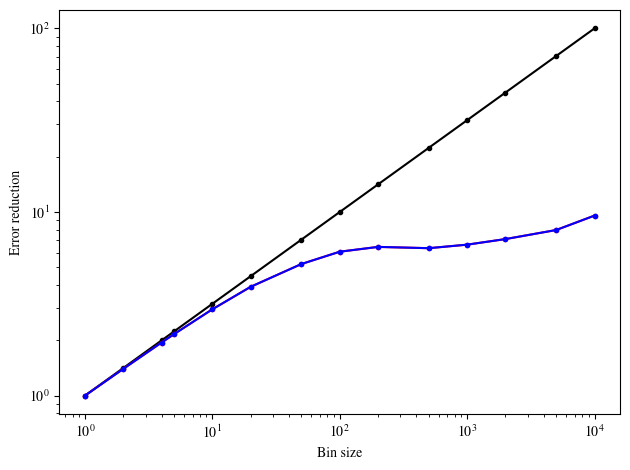

In [6]:

obs = jax.lax.map(lambda x: f(x, g_params), (conf), batch_size=1000)

error_jac, error_bi = [], []

for i in 1, 2, 4, 5, 10, 20, 50, 100,200, 500, 1000, 2000, 5000, 10000:
    jac, bi = jackknife(obs[:100000], Bs=i), bin(obs[:100000], Bs=i)
    print(f"jack bin size {i}: {jac}")
    print(f"bin size {i}: {bi}")
    error_jac.append(jac[1].real)
    error_bi.append(bi[1].real)

x_axis = np.array([1, 2, 4, 5, 10, 20, 50, 100,200, 500, 1000, 2000, 5000, 10000])

plt.plot(x_axis, np.sqrt(x_axis), color='black', marker='.', linestyle='-')
plt.plot(x_axis, np.array(error_jac)/error_jac[0], color='red', marker='.', linestyle='-')
plt.plot(x_axis, np.array(error_bi)/error_bi[0], color='blue', marker='.', linestyle='-')
plt.xscale('log')
plt.yscale('log')

plt.xlabel('Bin size')
plt.ylabel('Error reduction')
plt.tight_layout()
#plt.legend()
plt.show()

jack bin size 1: (np.complex64(-3.7289936e-07-2.1275944e-06j), np.complex128(1.2517819759975555e-06+1.7739685174608938e-06j))
bin size 1: (np.complex64(-3.7289936e-07-2.1275944e-06j), np.complex128(1.2517825106271405e-06+1.773973633314314e-06j))
jack bin size 2: (np.complex64(-3.7289936e-07-2.1275944e-06j), np.complex128(1.750023700339802e-06+2.476129080208468e-06j))
bin size 2: (np.complex64(-3.7289936e-07-2.1275944e-06j), np.complex128(1.7500226585388915e-06+2.4761275895052843e-06j))
jack bin size 4: (np.complex64(-3.7289936e-07-2.1275944e-06j), np.complex128(2.4347381879008787e-06+3.434080879411266e-06j))
bin size 4: (np.complex64(-3.7289936e-07-2.1275944e-06j), np.complex128(2.434741065954346e-06+3.434084296054211e-06j))
jack bin size 5: (np.complex64(-3.7289936e-07-2.1275944e-06j), np.complex128(2.700469910184311e-06+3.804716967651345e-06j))
bin size 5: (np.complex64(-3.7289936e-07-2.1275944e-06j), np.complex128(2.7004714556209917e-06+3.8047191223870575e-06j))
jack bin size 10: (n

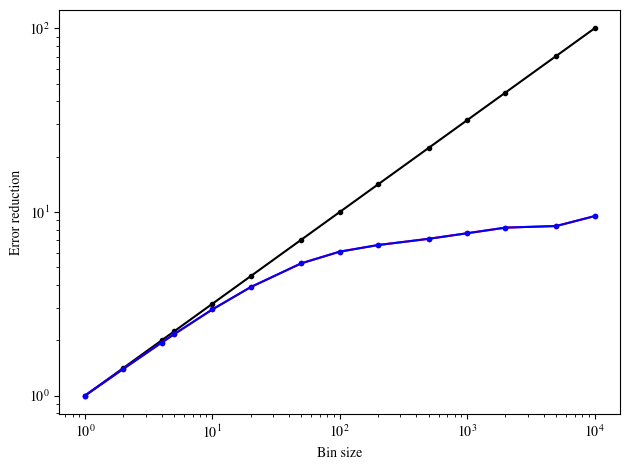

In [7]:

obs = jax.lax.map(lambda x: model.correlation(x, 4, av) - f(x, g_params), (conf), batch_size=1000)

error_jac, error_bi = [], []

for i in 1, 2, 4, 5, 10, 20, 50, 100,200, 500, 1000, 2000, 5000, 10000:
    jac, bi = jackknife(obs[:100000], Bs=i), bin(obs[:100000], Bs=i)
    print(f"jack bin size {i}: {jac}")
    print(f"bin size {i}: {bi}")
    error_jac.append(jac[1].real)
    error_bi.append(bi[1].real)

x_axis = np.array([1, 2, 4, 5, 10, 20, 50, 100,200, 500, 1000, 2000, 5000, 10000])

plt.plot(x_axis, np.sqrt(x_axis), color='black', marker='.', linestyle='-')
plt.plot(x_axis, np.array(error_jac)/error_jac[0], color='red', marker='.', linestyle='-')
plt.plot(x_axis, np.array(error_bi)/error_bi[0], color='blue', marker='.', linestyle='-')
plt.xscale('log')
plt.yscale('log')

plt.xlabel('Bin size')
plt.ylabel('Error reduction')
plt.tight_layout()
#plt.legend()
plt.show()

In [10]:
with open("correlated/u1_2d_obc/cv_4x1_5.55_new_l3_w32_lr1e-4_nt32_ridge0_test1e3_train1e4_sweep1_acc0.95_bs16_20min.pkl", "rb") as aa:
    g1, g_params, opt_state, track_red_temp, track_ltest_temp = pickle.load(aa)

track_ltest_temp[-1]

[217600, Array(0.00072766, dtype=float32)]